# Forecasting U.S. Payrolls

Sebastian Jaramillo

How much does a payroll forecast gain from production and prices, then from financial markets? Compare one-month forecasts for the same 216 first releases. Job counts below are in thousands. The historical cutoffs reproduce the release calendar. The input workbook contains subsequent revisions.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
from IPython.display import Image, display
from payroll_risk.data import PayrollPanel
from payroll_risk.study import evaluate, forecast

root = next(p for p in (Path.cwd(), *Path.cwd().parents, Path.cwd()/'project6')
            if (p/'results/cpi_coefficients.csv').is_file())
res = root/'results'
forecasts = pd.read_csv(res/'forecasts.csv')
primary = forecasts[forecasts.intensity == 0.5]
scores = evaluate(forecasts)
reference = pd.read_csv(res/'reference.csv')
models = ['AR','Macro','Full']
table = scores.query("episode == 'All' and intensity == 0.5 and vintage == 'first_release'")
display(table[['model','n','declines','rmse','mae','coverage','width','brier']].round(3))

,model,n,declines,rmse,mae,coverage,width,brier
0,AR,216,35,2187.449,466.923,0.954,1452.121,0.147
4,Macro,216,35,1647.445,380.297,0.963,1405.449,0.150
8,Full,216,35,1645.160,372.079,0.963,1374.481,0.141


## Reconstruct the information cutoff

Follow an origin through to its release. The last common input month precedes the target month, even if financial observations from part of the target month were available. Every model faces the same outcome and lead time.

,origin,target,payroll_release,cpi_release,ip_release,issue_date,target_release,lead_days
81,2013-09,2013-10,2013-10-22,2013-10-30,2013-10-28,2013-10-30,2013-11-08,9
159,2020-03,2020-04,2020-04-03,2020-04-10,2020-04-15,2020-04-15,2020-05-08,23
216,2026-03,2026-04,2026-04-03,2026-04-10,2026-04-16,2026-04-16,2026-05-08,22


Median historical lead: 18.0 days


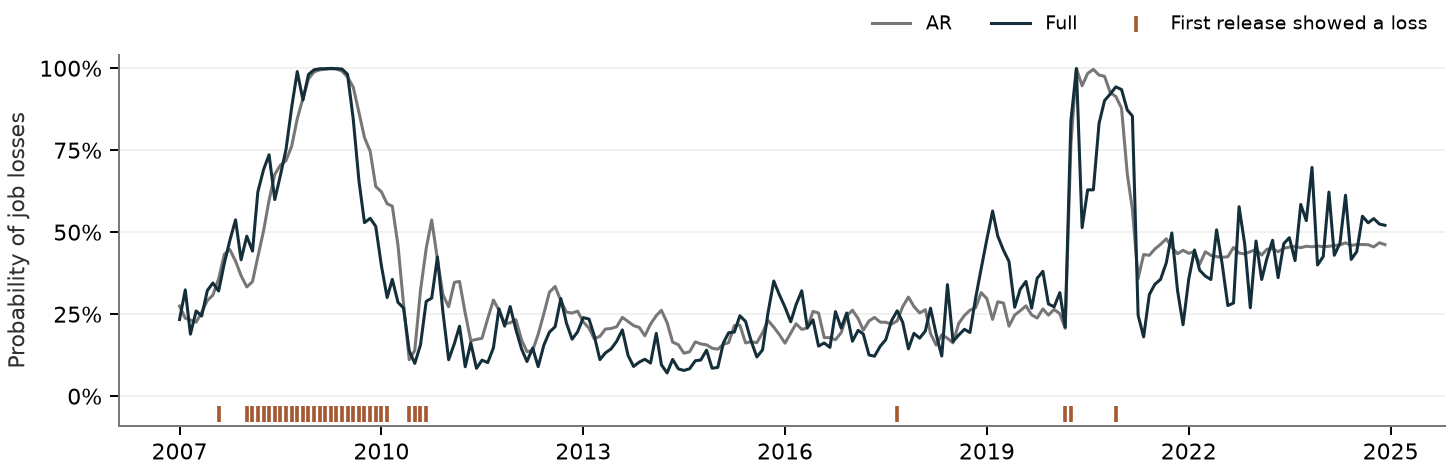

In [2]:
timing = pd.read_csv(root/'data/release_calendar.csv')
display(timing[timing.origin.isin(['2013-09','2020-03','2026-03'])])
assert (timing.issue_date < timing.target_release).all()
assert timing.origin.is_unique
print("Median historical lead:", timing.iloc[:-1].lead_days.median(), "days")
display(Image(filename=str(res/'figures/loss_probabilities.png'), width=750))

## Four releases that changed the averages

For each model, compare its predicted mean with the first announcement. Check how much of total squared error came from the four months shown in Figure 2.

model,AR,Macro,Full,First announcement
target,,,,
2020-03,182.0,150.0,169.0,-701
2020-04,-173.0,-166.0,-228.0,-20537
2020-05,-17433.0,-7374.0,-7321.0,2509
2020-06,-3929.0,241.0,-51.0,4800


model
AR       0.861
Full     0.912
Macro    0.911
Name: Share of total squared error, dtype: float64

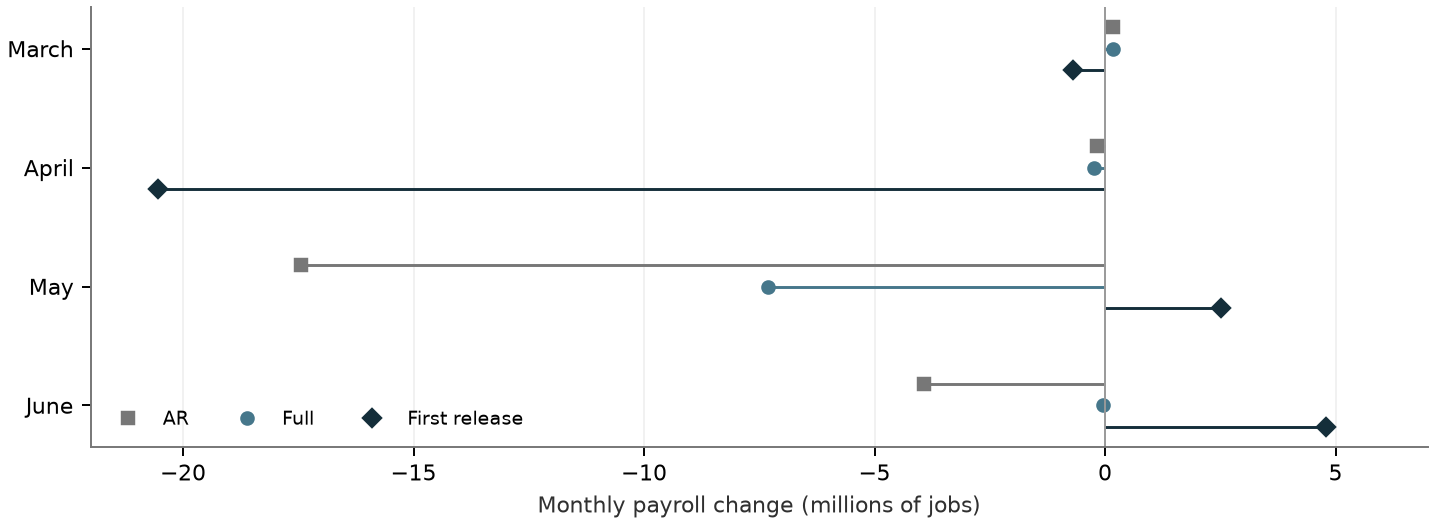

In [3]:
spring = primary[primary.target.between('2020-03','2020-06')]
comparison = spring.pivot(index='target', columns='model', values='mean')[models]
comparison['First announcement'] = spring.drop_duplicates('target').set_index('target').first_release
display(comparison.round())
error = primary.assign(squared=(primary['mean'] - primary.first_release)**2)
share = (error[error.target.between('2020-03','2020-06')].groupby('model').squared.sum()
         / error.groupby('model').squared.sum())
display(share.rename('Share of total squared error').round(3))
display(Image(filename=str(res/'figures/pandemic.png'), width=750))

## Does the ranking survive tighter shrinkage or a change in target vintage?

A first announcement measures the figure released to the public at the time. A revised change uses adjacent employment levels from the frozen panel. Lower RMSE and Brier scores are better.

In [4]:
display(scores.query("episode == 'All'").pivot(index=['vintage','intensity'],columns='model',
    values=['rmse','brier']).round(3))
replay = pd.read_csv(res/'replay_scores.csv').query("episode == 'All' and vintage == 'first_release'")
display(table[['model','rmse','brier']].merge(replay[['model','rmse','brier']],on='model',
                                            suffixes=('_main','_second_seed')).round(3))

rmse                      brier              
model                          AR      Full     Macro     AR   Full  Macro
vintage       intensity                                                   
first_release 0.1        1854.052  1604.757  1609.882  0.143  0.138  0.146
              0.5        2187.449  1645.160  1647.445  0.147  0.141  0.150
revised       0.1        1858.881  1607.125  1612.636  0.140  0.133  0.143
              0.5        2194.318  1649.181  1652.726  0.144  0.137  0.147

,model,rmse_main,brier_main,rmse_second_seed,brier_second_seed
0,AR,2187.449,0.147,2192.762,0.147
1,Macro,1647.445,0.150,1646.858,0.150
2,Full,1645.160,0.141,1638.210,0.141


## April 2026 at a fixed cutoff

Only this retrospective experiment replaces raw monthly observations from December 2019 through January 2022 with a straight path between the two adjacent observed endpoints. The reference forecast was reconstructed with inputs through March 2026. BLS first reported a gain of 115,000 jobs.

,training,model,mean,median,p05,p95,p_loss,cdf_115k
0,observed,AR,83.826,81.065,-1441.229,1618.296,0.465,0.515
2,observed,Macro,-44.706,-47.217,-1529.600,1448.749,0.521,0.571
4,observed,Full,-141.062,-143.399,-1580.561,1306.404,0.565,0.616
6,interpolated,AR,46.070,45.911,-322.483,415.163,0.419,0.621
8,interpolated,Macro,10.041,9.913,-350.582,371.104,0.482,0.684
10,interpolated,Full,46.436,46.294,-302.465,395.820,0.414,0.627


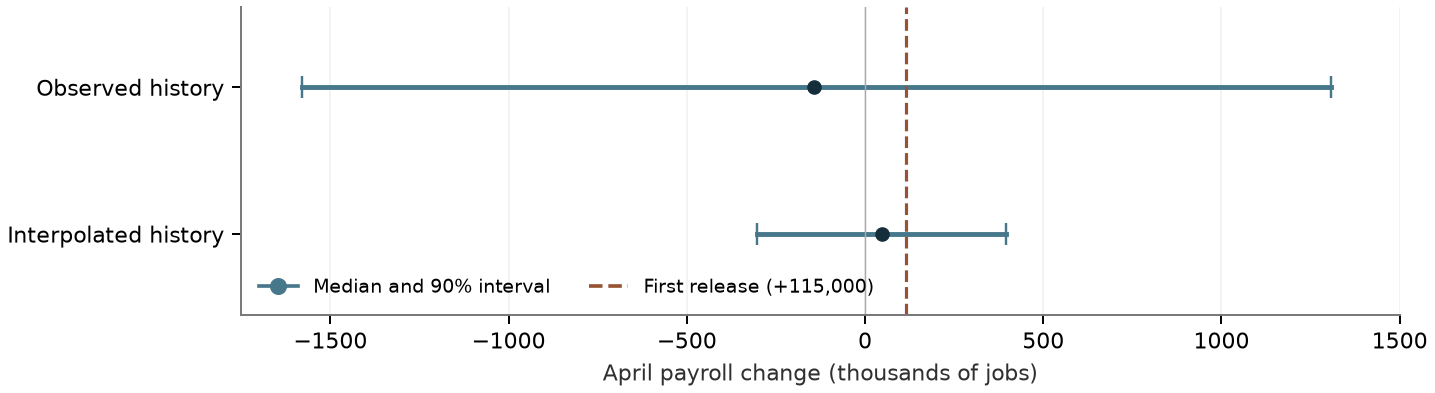

,lag,median,p05,p95,r_hat
0,1,-0.0122,-0.0377,0.0133,1.0000
1,2,-0.0005,-0.0267,0.0250,1.0000
2,3,0.0105,-0.0095,0.0300,0.9998


In [5]:
cols = ['training','model','mean','median','p05','p95','p_loss','cdf_115k']
display(reference[reference.intensity==0.5][cols].round(3))
display(Image(filename=str(res/'figures/april_reference.png'), width=740))
coefficients = pd.read_csv(res/'cpi_coefficients.csv').query("intensity == 0.5 and training == 'observed'")
display(coefficients[['lag','median','p05','p95','r_hat']].round(4))

## Check one reference fit

Set the environment variable PAYROLL_WORKBOOK to the frozen input to rerun the five-variable model below. Without it, the numerical checks and tables above use the published results. The code compares the re-estimated predictive summaries to their recorded values.

In [6]:
record = reference.query("model == 'Full' and intensity == 0.5 and training == 'observed'").iloc[0]
if workbook := os.environ.get('PAYROLL_WORKBOOK'):
    panel = PayrollPanel.load(workbook)
    values = panel.design('2026-03', 'Full')
    run, _ = forecast(('2026-03', 'Full', .5, 'observed', values, True))
    keys = ['mean','median','p05','p95','p_loss']
    display(pd.DataFrame({'published': record[keys].astype(float),
                          'recomputed': {k:run[k] for k in keys}}).round(4))
    np.testing.assert_allclose([run[k] for k in keys], record[keys].astype(float), rtol=1e-7)
else:
    print("Set PAYROLL_WORKBOOK to enable the optional reference refit.")
assert forecasts.max_rhat.max() <= 1.01 and forecasts.min_ess_bulk.min() >= 400
assert forecasts.min_ess_tail.min() >= 400

,published,recomputed
mean,-141.0625,-141.0625
median,-143.3993,-143.3993
p05,-1580.5609,-1580.5609
p95,1306.4043,1306.4043
p_loss,0.5649,0.5649


The improvement from adding production and prices persisted in the second simulation. Financial indicators changed point accuracy little relative to that gain. The spring 2020 misses and the sensitivity of the April 2026 loss probability illustrate the cost of fitting a common innovation covariance across very different regimes.

[Research report](../docs/payroll_forecasts.pdf) · [Data contract and sources](../data/README.md) · [Historical scorecard](../results/scores.csv)